# 03 · The shop: forecasting, safety stock and stockouts

Every safe room is a branch of the same shop. It runs a textbook **periodic-review inventory policy**:

1. Other crawlers (and you) buy items over the floor. Demand nobody could fill is a **lost sale**.
2. The shop updates its **forecast** of demand per floor with exponential smoothing.
3. Last floor's order arrives (the **lead time** is one floor).
4. If stock is at or below the **reorder point**, it orders enough to reach the **order-up-to level**.

$$\text{reorder point} = \underbrace{f \times L}_{\text{expected demand over lead time}} + \underbrace{z\sqrt{f \times L}}_{\text{safety stock}}$$

with $f$ the forecast, $L = 1$ floor and $z = 1$ (demand is Poisson, so its variance equals its mean). This notebook asks how good the forecasts are, what service the shop actually delivers, and what it would cost to do better. The same questions apply to any FMCG replenishment process.

The data has one row per item per floor turnover, across 2,000 bot runs.

In [1]:
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from common import MUTED, SEQUENTIAL, SERIES, TEXT_2, load, pct_axis, style
from crawler.items import ITEMS
from crawler.shop import ALPHA, BASE_DEMAND, LEAD_TIME, SAFETY_Z

style()
shop = load("shop")
shop["name"] = shop["item"].map(lambda k: ITEMS[k]["name"])
shop["error"] = shop["forecast_before"] - shop["demand"]        # + over-forecast, - under-forecast
print(f"{len(shop):,} item-floor rows; forecast smoothing alpha = {ALPHA}, safety z = {SAFETY_Z}")
shop[["run_id", "depth", "name", "demand", "forecast_before", "sales", "lost", "on_hand", "ordered"]].head()

79,083 item-floor rows; forecast smoothing alpha = 0.3, safety z = 1.0


,run_id,depth,name,demand,forecast_before,sales,lost,on_hand,ordered
0,bot00000,1,Fizzy Tonic,4,3.0,4,0,5,5
1,bot00000,1,Sponsor Brew,1,1.5,1,0,4,0
2,bot00000,1,Producer's Elixir,1,0.5,1,0,1,2
3,bot00000,1,Party Popper Bomb,1,1.5,1,0,4,0
4,bot00000,1,Crate of Fireworks,1,0.7,1,0,2,0


## 1. How accurate are the forecasts?

Four common measures, each answering a different question:

| Measure | Formula | Question it answers |
|---|---|---|
| **Bias** | mean(forecast - actual) | Do we lean high or low? |
| **MAE** | mean(\|forecast - actual\|) | How far off are we, in units? |
| **WAPE** | sum(\|error\|) / sum(actual) | How far off, relative to volume? |
| **MAPE** | mean(\|error\| / actual) | The average percentage error per period |

MAPE is popular but breaks on **intermittent demand**: any period with zero sales divides by zero, and it has to be dropped. That's why the table also shows how often each item sold nothing.

In [2]:
def accuracy(g):
    nz = g[g["demand"] > 0]
    return pd.Series(dict(
        mean_demand=g["demand"].mean(),
        zero_demand_floors=(g["demand"] == 0).mean(),
        bias=g["error"].mean(),
        mae=g["error"].abs().mean(),
        wape=g["error"].abs().sum() / g["demand"].sum(),
        mape_nonzero=(nz["error"].abs() / nz["demand"]).mean(),
    ))

acc = shop.groupby("name").apply(accuracy, include_groups=False).sort_values("mean_demand", ascending=False)
acc.style.format({"mean_demand": "{:.2f}", "zero_demand_floors": "{:.0%}", "bias": "{:+.2f}",
                  "mae": "{:.2f}", "wape": "{:.0%}", "mape_nonzero": "{:.0%}"})

,mean_demand,zero_demand_floors,bias,mae,wape,mape_nonzero
name,,,,,,
Fizzy Tonic,3.91,2%,-0.62,1.68,43%,51%
Sponsor Brew,2.00,13%,-0.33,1.17,59%,48%
Party Popper Bomb,1.92,15%,-0.30,1.16,60%,47%
Padded Gym Jersey,1.04,36%,-0.16,0.85,81%,43%
Dented Frying Pan,1.03,36%,-0.16,0.84,82%,43%
Crate of Fireworks,0.90,41%,-0.14,0.78,87%,45%
Producer's Elixir,0.79,47%,-0.20,0.78,98%,56%
Riot Vest,0.66,52%,-0.11,0.69,104%,56%
Pocket Cleaver,0.51,60%,-0.08,0.60,117%,62%


**Every item is under-forecast.** Bias is negative across the board. The cause is visible below: demand rises as crawlers go deeper (the game grows it 10% per floor), and simple exponential smoothing always trails a trend. It's a weighted average of the *past*, so in a rising market it's always a step behind.

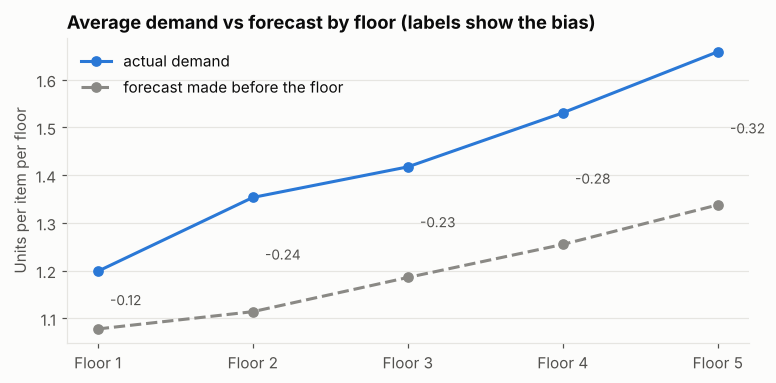

In [3]:
by_floor = shop.groupby("depth").agg(actual=("demand", "mean"), forecast=("forecast_before", "mean"))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(by_floor.index, by_floor["actual"], marker="o", color=SEQUENTIAL, label="actual demand")
ax.plot(by_floor.index, by_floor["forecast"], marker="o", color=MUTED, linestyle="--", label="forecast made before the floor")
for x, r in by_floor.iterrows():
    ax.annotate(f"{r['forecast'] - r['actual']:+.2f}", (x, (r["forecast"] + r["actual"]) / 2), xytext=(8, 0),
                textcoords="offset points", va="center", color=TEXT_2, fontsize=9)
ax.set_xticks(by_floor.index, [f"Floor {k}" for k in by_floor.index])
ax.set_ylabel("Units per item per floor")
ax.legend(loc="upper left")
ax.set_title("Average demand vs forecast by floor (labels show the bias)")
plt.show()

## 2. Could a different forecast do better?

We replay every item's demand history through several methods, each starting from the shop's initial estimate:

- **Naive:** next floor = last floor's demand.
- **Exponential smoothing (SES)** with different $\alpha$. High $\alpha$ reacts fast but chases noise; low $\alpha$ is smooth but slow.
- **SES + growth:** the shop's own method, multiplied by the known 10% per floor growth. This is a simple way to put the trend back in.

In [4]:
GROWTH = 1.10
series = (shop.sort_values("depth").groupby(["run_id", "item"])["demand"].apply(list))

def backtest(method, alpha=ALPHA):
    errs, actual = [], []
    for (run, item), demand in series.items():
        f = BASE_DEMAND[item]
        last = None
        for d in demand:
            if method == "naive":
                pred = BASE_DEMAND[item] if last is None else last
            elif method == "ses+growth":
                pred = f * GROWTH
            else:
                pred = f
            errs.append(pred - d)
            actual.append(d)
            f = alpha * d + (1 - alpha) * f
            last = d
    errs, actual = np.array(errs), np.array(actual)
    return dict(bias=errs.mean(), mae=np.abs(errs).mean(), wape=np.abs(errs).sum() / actual.sum())

methods = [("naive", None)] + [("ses", a) for a in (0.1, 0.3, 0.5, 0.8)] + [("ses+growth", ALPHA)]
rows = []
for m, a in methods:
    label = m if a is None else f"{m} (alpha {a})"
    if m == "ses" and a == ALPHA:
        label += "  <- the shop today"
    rows.append(dict(method=label, **backtest(m, a if a is not None else ALPHA)))
pd.DataFrame(rows).set_index("method").style.format({"bias": "{:+.3f}", "mae": "{:.3f}", "wape": "{:.1%}"})

,bias,mae,wape
method,,,
naive,-0.117,1.124,79.3%
ses (alpha 0.1),-0.299,0.931,65.6%
ses (alpha 0.3) <- the shop today,-0.232,0.950,67.0%
ses (alpha 0.5),-0.185,0.991,69.9%
ses (alpha 0.8),-0.137,1.070,75.4%
ses+growth (alpha 0.3),-0.114,0.953,67.2%


Adding the growth factor roughly halves the bias. The rest comes from demand the factor doesn't model, such as the player's own purchases. WAPE barely moves, though: on small, noisy Poisson counts, most of the error is pure randomness that no method can predict. That's the **irreducible error**. A forecast can be *unbiased* without being *precise*, and the next two sections show why that distinction matters for stock.

## 3. What service does the shop actually give?

Two standard service measures:

- **Fill rate:** the share of demand served from stock, $\text{sales} / \text{demand}$.
- **Cycle service level (CSL):** the share of floors with no stockout at all.

With $z = 1$, textbook theory (assuming a normal distribution) promises a CSL of about 84%. Let's see what it delivers.

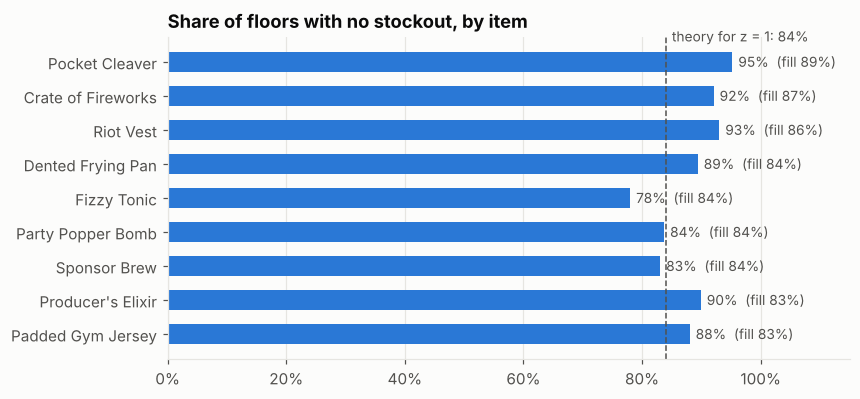

In [5]:
svc = shop.groupby("name").agg(demand=("demand", "sum"), sales=("sales", "sum"),
                               stockout_floors=("lost", lambda l: (l > 0).mean()))
svc["fill_rate"] = svc["sales"] / svc["demand"]
svc["cycle_service_level"] = 1 - svc["stockout_floors"]
svc = svc.sort_values("fill_rate")

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(svc))
ax.barh(y, svc["cycle_service_level"], color=SEQUENTIAL, height=0.6)
ax.axvline(0.84, color=TEXT_2, linewidth=1, linestyle="--")
ax.annotate("theory for z = 1: 84%", (0.84, len(svc) - 0.4), xytext=(4, 0), textcoords="offset points",
            color=TEXT_2, fontsize=9)
for yy, (name, r) in zip(y, svc.iterrows()):
    ax.annotate(f"{r['cycle_service_level']:.0%}  (fill {r['fill_rate']:.0%})", (r["cycle_service_level"], yy),
                xytext=(4, 0), textcoords="offset points", va="center", color=TEXT_2, fontsize=9)
ax.set_yticks(y, svc.index)
ax.set_xlim(0, 1.15)
pct_axis(ax, "x")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_title("Share of floors with no stockout, by item")
plt.show()

The fastest mover, Fizzy Tonic, falls short of 84%. The other fast movers land roughly on target, and the slow movers beat theory comfortably. Two forces are at work:

1. **Bias.** The reorder point is built on a forecast that's too low, so part of the safety stock gets used up covering the trend instead of covering randomness. It hurts most where volumes are highest.
2. **Rounding.** Stock comes in whole units, and orders are rounded up. For a slow mover, rounding 0.9 units up to 1 is a big relative cushion, so slow movers end up better protected than the formula intends.

## 4. The trade-off: stock vs service

Higher $z$ means more safety stock: better service, but more money tied up on the shelf. We replay each item's real demand history through the shop's policy at different $z$ values and measure two things: average units on hand, and fill rate. The curve that results is the **efficient frontier** of the policy.

Then we repeat it with the bias-corrected forecast (SES + growth). The question: does a less biased forecast shift the whole curve (the same service for less stock), or just move us along it?

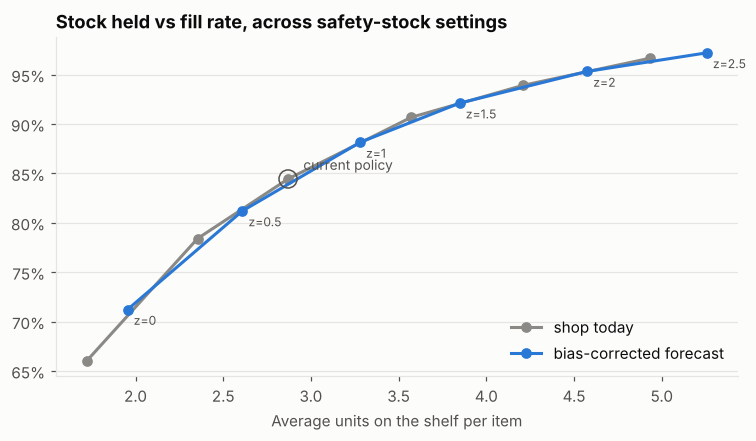

method,bias-corrected forecast,shop today
z,,
z = 0,71.2%,66.0%
z = 0.5,81.2%,78.4%
z = 1,88.1%,84.4%
z = 1.5,92.1%,90.7%
z = 2,95.3%,93.9%
z = 2.5,97.2%,96.7%


In [6]:
def replay(z, growth=1.0, alpha=ALPHA):
    on_hand_total = sales_total = demand_total = periods = 0
    for (run, item), demand in series.items():
        f = BASE_DEMAND[item]
        out = lambda f: f * growth * (LEAD_TIME + 1) + z * math.sqrt(f * growth * (LEAD_TIME + 1))
        rop = lambda f: f * growth * LEAD_TIME + z * math.sqrt(f * growth * LEAD_TIME)
        stock, on_order = math.ceil(out(f)), 0
        for d in demand:
            sold = min(stock, d)
            stock -= sold
            sales_total += sold
            demand_total += d
            f = alpha * d + (1 - alpha) * f
            stock, on_order = stock + on_order, 0
            if stock <= rop(f):
                on_order = max(0, math.ceil(out(f) - stock))
            on_hand_total += stock
            periods += 1
    return on_hand_total / periods, sales_total / demand_total

zs = [0, 0.5, 1.0, 1.5, 2.0, 2.5]
frontier = pd.DataFrame([dict(z=z, method=label, **dict(zip(["avg_stock", "fill_rate"], replay(z, g))))
                         for label, g in [("shop today", 1.0), ("bias-corrected forecast", GROWTH)]
                         for z in zs])

fig, ax = plt.subplots(figsize=(8, 4))
for (label, g), colour in zip(frontier.groupby("method", sort=False), [MUTED, SEQUENTIAL]):
    ax.plot(g["avg_stock"], g["fill_rate"], marker="o", color=colour, label=label)
    for _, r in g.iterrows():
        if label == "bias-corrected forecast":
            ax.annotate(f"z={r['z']:g}", (r["avg_stock"], r["fill_rate"]), xytext=(4, -10),
                        textcoords="offset points", color=TEXT_2, fontsize=8)
today = frontier[(frontier["method"] == "shop today") & (frontier["z"] == SAFETY_Z)].iloc[0]
ax.scatter([today["avg_stock"]], [today["fill_rate"]], s=140, facecolors="none", edgecolors=TEXT_2, zorder=4)
ax.annotate("current policy", (today["avg_stock"], today["fill_rate"]), xytext=(10, 6), textcoords="offset points",
            color=TEXT_2, fontsize=9)
ax.set_xlabel("Average units on the shelf per item")
pct_axis(ax)
ax.legend(loc="lower right")
ax.set_title("Stock held vs fill rate, across safety-stock settings")
plt.show()
frontier.assign(z=frontier["z"].map("z = {:g}".format)).pivot(index="z", columns="method", values="fill_rate").style.format("{:.1%}")

**What to take from it**

- More safety stock buys service with diminishing returns: each extra step of $z$ costs more stock for a smaller gain.
- **Correcting the bias doesn't shift the curve; it slides you along it.** At $z = 1$ the corrected forecast gives about 88% fill instead of 84%, but only because it holds more stock, exactly what raising $z$ would do. In this policy an under-forecast behaves like a hidden cut to safety stock. Fixing it restores the service level you *thought* you'd set, but it isn't free stock reduction.
- To truly shift the frontier you need a more **precise** forecast: a smaller spread of errors, not just a centred one. Here demand is Poisson noise that can't be predicted, so no forecast can do that. In real FMCG supply chains, that's where the value of better data lies: promotions, events and weather explain demand that would otherwise look like noise.
- The current setting gives about 84% fill with roughly 2.9 units of each item on the shelf. Pushing to 95% would take over 50% more stock.

## 5. For the player: when is the shop likely to be out?

The bottom line for your run. This is the chance each item is out of stock when you arrive at a floor's safe room. It's stock *after* the delivery, before anyone has bought on that floor.

In [7]:
arrive = shop.copy()
arrive["next_floor"] = arrive["depth"] + 1                 # this stock is what floor depth+1 opens with
out = arrive.assign(sold_out=arrive["on_hand"] == 0).pivot_table(
    index="name", columns="next_floor", values="sold_out", aggfunc="mean")
out.columns = [f"Floor {c}" for c in out.columns]
out = out.loc[out.mean(axis=1).sort_values(ascending=False).index]
out.style.format("{:.0%}").background_gradient(cmap="Blues", vmin=0, vmax=0.5)

,Floor 2,Floor 3,Floor 4,Floor 5,Floor 6
name,,,,,
Producer's Elixir,13%,11%,8%,10%,12%
Padded Gym Jersey,6%,13%,10%,10%,8%
Dented Frying Pan,7%,12%,9%,7%,10%
Riot Vest,11%,8%,6%,7%,9%
Sponsor Brew,3%,14%,8%,7%,9%
Party Popper Bomb,3%,11%,9%,8%,8%
Crate of Fireworks,4%,10%,7%,6%,9%
Fizzy Tonic,1%,6%,6%,10%,8%
Pocket Cleaver,7%,6%,5%,5%,6%
